In [21]:
pip install pandas numpy scikit-learn matplotlib seaborn statsmodels


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# Load CSV and set date as index
df = pd.read_csv('modelling_dataset.csv', parse_dates=['date'])
df = df.sort_values('date').set_index('date')

# Drop rows with NaN from lag/rolling features (first ~30 days)
df = df.dropna()

# Create day-of-week dummies (Monday is baseline; columns dow_1 ... dow_6)
df = pd.get_dummies(df, columns=['day_of_week'], prefix='dow', drop_first=True, dtype=int)

print(df.shape)
print(df.head())

(3622, 30)
             avg_price  median_price  min_price  max_price  num_stations  \
date                                                                       
2016-07-31  112.079872         113.9       99.8      125.9           313   
2016-08-01  109.745048         111.9       97.8      125.9           313   
2016-08-02  122.786262         124.9       97.7      129.9           313   
2016-08-03  119.764856         121.9       96.8      125.9           313   
2016-08-04  117.103195         119.9       96.3      125.9           313   

            target_next_day       lag_1       lag_2       lag_3       lag_7  \
date                                                                          
2016-07-31       109.745048  113.871246  115.792652  119.152396  114.257188   
2016-08-01       122.786262  112.079872  113.871246  115.792652  112.190415   
2016-08-02       119.764856  109.745048  112.079872  113.871246  124.327157   
2016-08-03       117.103195  122.786262  109.745048  112.0798

In [23]:
base_features = [
    'avg_price',          # today's price — keep this as the level term
    # 'lag_7',            # REMOVED: VIF = inf (collinear with avg_price - price_change_7d)
    # 'rolling_mean_7',   # REMOVED: VIF = 1948 (smoothed duplicate of avg_price)
    'rolling_std_7',      # short-term volatility
    'price_change_1d',    # daily momentum
    'price_change_7d',    # weekly momentum (we keep this; the level info is in avg_price)
    'brent_price_usd',
    'aud_per_usd',
]

dow_features = [col for col in df.columns if col.startswith('dow_')]
feature_cols = base_features + dow_features

print("Features used:", feature_cols)
print("Number of features:", len(feature_cols))

Features used: ['avg_price', 'rolling_std_7', 'price_change_1d', 'price_change_7d', 'brent_price_usd', 'aud_per_usd', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6']
Number of features: 12


In [24]:
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

X_train = train[feature_cols].astype(float)
y_train = train['target_next_day']

X_val   = val[feature_cols].astype(float)
y_val   = val['target_next_day']

X_test  = test[feature_cols].astype(float)
y_test  = test['target_next_day']

print(f"Train size: {len(train)}, Val size: {len(val)}, Test size: {len(test)}")

Train size: 2535, Val size: 543, Test size: 544


In [25]:
X_train_const = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        target_next_day   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     3166.
Date:                Wed, 23 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:35:53   Log-Likelihood:                -8172.0
No. Observations:                2535   AIC:                         1.637e+04
Df Residuals:                    2522   BIC:                         1.645e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              42.2077      3.298     

In [26]:
vif_data = pd.DataFrame()
vif_data['feature'] = X_train.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

print("\nVariance Inflation Factors:")
print(vif_data.sort_values('VIF', ascending=False))


Variance Inflation Factors:
            feature         VIF
0         avg_price  152.581377
4   brent_price_usd   59.819436
5       aud_per_usd   45.102559
1     rolling_std_7   12.557698
7             dow_2    2.738508
6             dow_1    2.402187
8             dow_3    2.308593
9             dow_4    2.177932
10            dow_5    2.073328
11            dow_6    2.021779
2   price_change_1d    1.812607
3   price_change_7d    1.209446


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Validation
y_pred_val = model.predict(sm.add_constant(X_val))
mae_val  = mean_absolute_error(y_val, y_pred_val)
rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2_val   = r2_score(y_val, y_pred_val)

# Test
y_pred_test = model.predict(sm.add_constant(X_test))
mae_test  = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test   = r2_score(y_test, y_pred_test)

print(f"Val  — MAE: {mae_val:.3f}, RMSE: {rmse_val:.3f}, R²: {r2_val:.4f}")
print(f"Test — MAE: {mae_test:.3f}, RMSE: {rmse_test:.3f}, R²: {r2_test:.4f}")

Val  — MAE: 6.863, RMSE: 9.175, R²: 0.5847
Test — MAE: 6.617, RMSE: 8.081, R²: 0.8066


In [28]:
# Naive: tomorrow = today's price
naive_val  = X_val['avg_price']
naive_test = X_test['avg_price']

print("Naive Val  MAE:", mean_absolute_error(y_val, naive_val))
print("Naive Test MAE:", mean_absolute_error(y_test, naive_test))

Naive Val  MAE: 9.532354355146264
Naive Test MAE: 6.798946151222742


In [29]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

test_eval = pd.DataFrame({
    'date': X_test.index,
    'actual': y_test.values,
    'pred_ols': y_pred_test,
    'pred_naive': X_test['avg_price'].values,
})

# Define regimes — adjust dates to match your actual test range
test_eval['regime'] = 'normal'
test_eval.loc[test_eval['date'] >= '2026-03-01', 'regime'] = 'shock'
test_eval.loc[test_eval['date'] >= '2026-05-01', 'regime'] = 'post_shock'

for regime in test_eval['regime'].unique():
    sub = test_eval[test_eval['regime'] == regime]
    mae_ols   = mean_absolute_error(sub['actual'], sub['pred_ols'])
    mae_naive = mean_absolute_error(sub['actual'], sub['pred_naive'])
    rmse_ols  = root_mean_squared_error(sub['actual'], sub['pred_ols'])
    print(f"{regime:12s} | n={len(sub):4d} | OLS MAE={mae_ols:6.2f} | "
          f"Naive MAE={mae_naive:6.2f} | RMSE={rmse_ols:6.2f} | "
          f"delta={mae_naive-mae_ols:+.2f}")

normal       | n= 422 | OLS MAE=  6.71 | Naive MAE=  7.68 | RMSE=  8.09 | delta=+0.97
shock        | n=  61 | OLS MAE=  8.74 | Naive MAE=  4.10 | RMSE= 10.23 | delta=-4.64
post_shock   | n=  61 | OLS MAE=  3.83 | Naive MAE=  3.39 | RMSE=  5.05 | delta=-0.44


Test period: 2025-01-03 → 2026-06-30
Test MAE (OLS)  : 6.617
Test MAE (naive): 6.799
Saved test_eval.csv


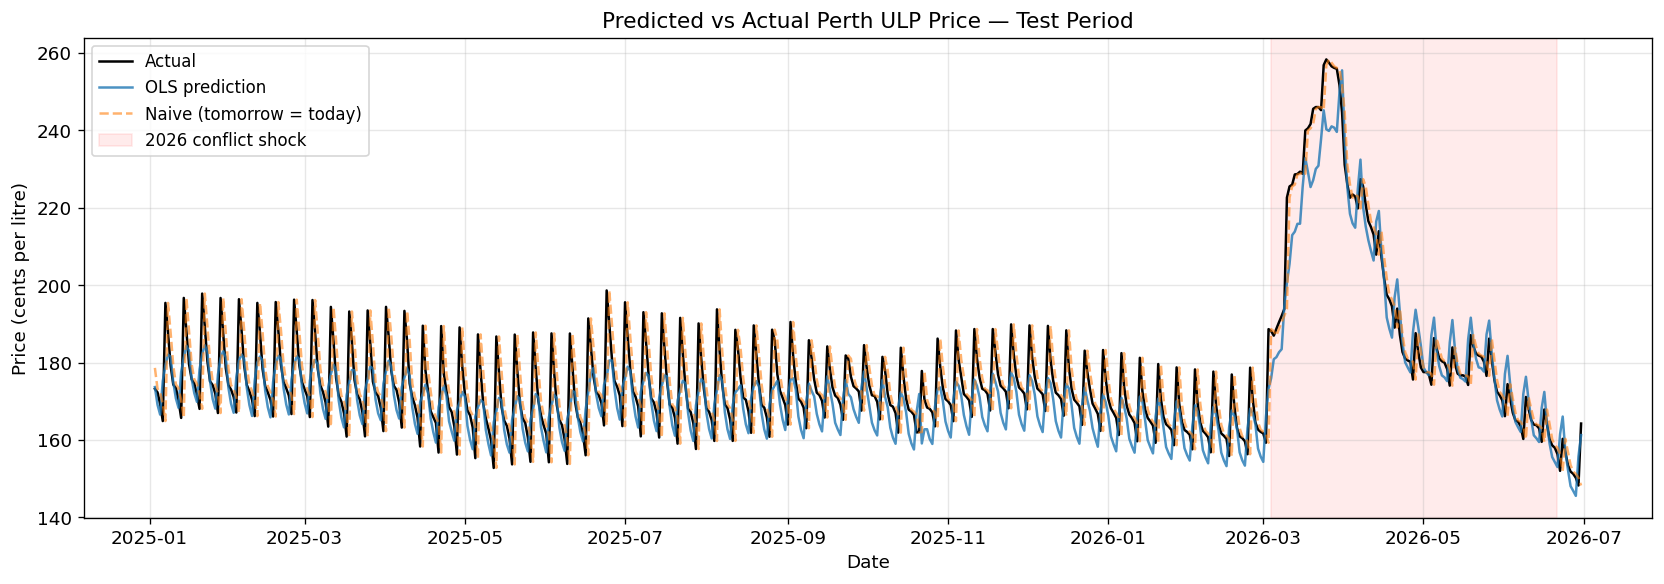

In [30]:
# =========================================================
# One-shot: rebuild model, evaluate, and plot test predictions
# =========================================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------- 1. Load & prepare ----------
df = pd.read_csv('modelling_dataset.csv', parse_dates=['date'])
df = df.sort_values('date').set_index('date')
df = df.dropna()
df = pd.get_dummies(df, columns=['day_of_week'],
                    prefix='dow', drop_first=True, dtype=int)

# ---------- 2. Features ----------
base_features = [
    'avg_price',
    'rolling_std_7',
    'price_change_1d',
    'price_change_7d',
    'brent_price_usd',
    'aud_per_usd',
]
dow_features = [c for c in df.columns if c.startswith('dow_')]
feature_cols = base_features + dow_features

# ---------- 3. Split ----------
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

X_train = train[feature_cols].astype(float)
y_train = train['target_next_day']
X_val   = val[feature_cols].astype(float)
y_val   = val['target_next_day']
X_test  = test[feature_cols].astype(float)
y_test  = test['target_next_day']

# ---------- 4. Fit OLS ----------
X_train_const = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_const).fit()

# ---------- 5. Predict ----------
y_pred_test = model.predict(sm.add_constant(X_test))
y_pred_val  = model.predict(sm.add_constant(X_val))

print(f"Test period: {X_test.index.min().date()} → {X_test.index.max().date()}")
print(f"Test MAE (OLS)  : {mean_absolute_error(y_test, y_pred_test):.3f}")
print(f"Test MAE (naive): {mean_absolute_error(y_test, X_test['avg_price']):.3f}")

# ---------- 6. Evaluation frame ----------
test_eval = pd.DataFrame({
    'date':       pd.to_datetime(X_test.index),
    'actual':     y_test.values,
    'pred_ols':   y_pred_test,
    'pred_naive': X_test['avg_price'].values,
})

# Regime labels
test_eval['regime'] = 'normal'
test_eval.loc[test_eval['date'] >= '2026-03-04', 'regime'] = 'shock'
test_eval.loc[test_eval['date'] >= '2026-06-21', 'regime'] = 'post_shock'

# Save for next time
test_eval.to_csv('test_eval.csv', index=False)
print("Saved test_eval.csv")

# =========================================================
# GRAPH: Actual vs Predicted with regime shading
# =========================================================
shock_start = pd.Timestamp('2026-03-04')
shock_end   = pd.Timestamp('2026-06-21')

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test_eval['date'], test_eval['actual'],
        label='Actual', color='black', linewidth=1.5)
ax.plot(test_eval['date'], test_eval['pred_ols'],
        label='OLS prediction', color='tab:blue', alpha=0.8)
ax.plot(test_eval['date'], test_eval['pred_naive'],
        label='Naive (tomorrow = today)',
        color='tab:orange', alpha=0.6, linestyle='--')

ax.axvspan(shock_start, shock_end, color='red', alpha=0.08,
           label='2026 conflict shock')

ax.set_title('Predicted vs Actual Perth ULP Price — Test Period', fontsize=13)
ax.set_ylabel('Price (cents per litre)')
ax.set_xlabel('Date')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_test_predictions.png', dpi=150)
plt.show()

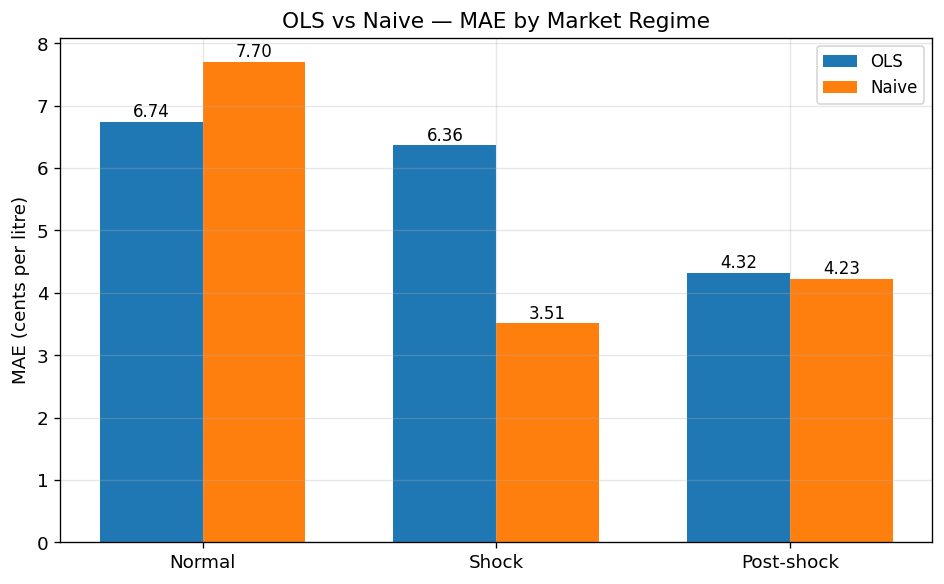

In [31]:
# Metrics by regime (recompute from test_eval)
from sklearn.metrics import mean_absolute_error

regimes = ['normal', 'shock', 'post_shock']
labels  = ['Normal', 'Shock', 'Post-shock']

mae_ols   = []
mae_naive = []

for r in regimes:
    sub = test_eval[test_eval['regime'] == r]
    mae_ols.append(mean_absolute_error(sub['actual'], sub['pred_ols']))
    mae_naive.append(mean_absolute_error(sub['actual'], sub['pred_naive']))

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - width/2, mae_ols,   width, label='OLS',   color='tab:blue')
b2 = ax.bar(x + width/2, mae_naive, width, label='Naive', color='tab:orange')

for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f'{bar.get_height():.2f}',
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('MAE (cents per litre)')
ax.set_title('OLS vs Naive — MAE by Market Regime', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('fig2_mae_regime.png', dpi=150)
plt.show()

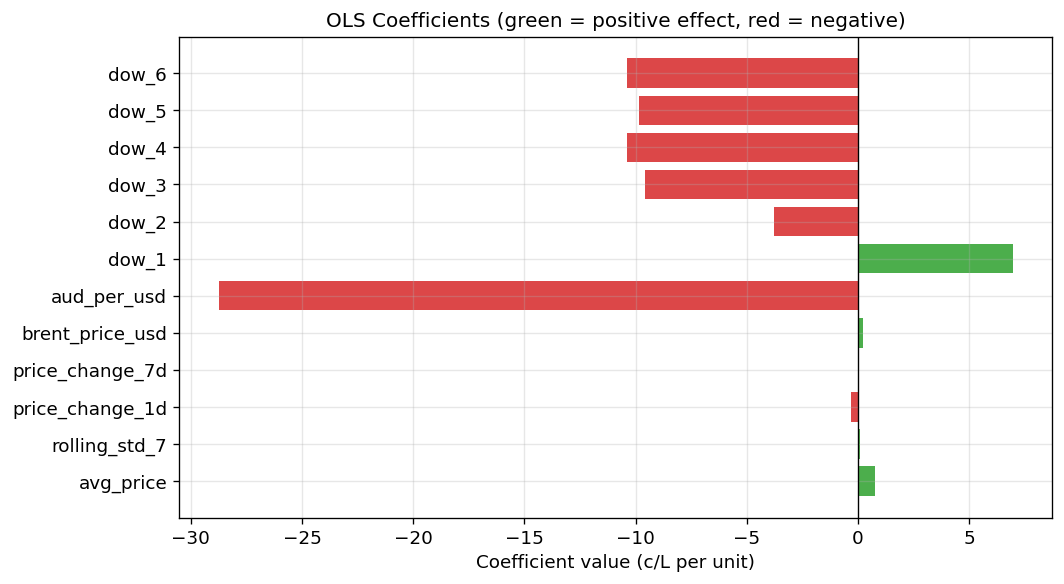

In [32]:
# --- Refit OLS if model not in memory ---
df = pd.read_csv('modelling_dataset.csv', parse_dates=['date'])
df = df.sort_values('date').set_index('date').dropna()
df = pd.get_dummies(df, columns=['day_of_week'],
                    prefix='dow', drop_first=True, dtype=int)

features = [
    'avg_price', 'rolling_std_7', 'price_change_1d', 'price_change_7d',
    'brent_price_usd', 'aud_per_usd',
] + [c for c in df.columns if c.startswith('dow_')]

n = len(df)
train = df.iloc[:int(n * 0.70)]
X_train = train[features].astype(float)
y_train = train['target_next_day']

model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
# ------------------------------------------

# Plot
coef = model.params.drop('const')
colors = ['tab:red' if v < 0 else 'tab:green' for v in coef]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coef.index, coef.values, color=colors, alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient value (c/L per unit)')
ax.set_title('OLS Coefficients (green = positive effect, red = negative)',
             fontsize=12)
plt.tight_layout()
plt.savefig('fig3_coefficients.png', dpi=150)
plt.show()